In [9]:
import pandas as pd 
import networkx as nx 
import numpy as np 
from sklearn.metrics import roc_auc_score

In [ ]:
DATA_DIR = "../data_collection/data/"
nodes = pd.read_csv(DATA_DIR + "twitch_nodes.csv")
edgelist = pd.read_csv(DATA_DIR + "twitch_edgelist.csv")

In [11]:
edgelist.head(3)

,Source,Target,Type,Weight
0,273316640,207277102,Directed,1
1,61294188,17182295,Directed,1
2,55743821,108547363,Directed,1


In [12]:
nodes.head(5)

,ID,Label,Broadcaster_Type,Total_Followers
0,77827128,Tumblurr,partner,2006052
1,539141014,aNcMedia,partner,4582
2,179279586,Kertus,partner,170260
3,212737350,NinjoTv,partner,112211
4,20844000,JodyJDC,partner,163204


In [13]:
G = nx.from_pandas_edgelist(
    edgelist,
    source='Source',
    target='Target',
    create_using=nx.Graph() 
)

node_attributes = nodes.set_index('ID').to_dict(orient='index') #creo un dizionario dove la key è l'ID ed i values sono gli attributi del nodo 
nx.set_node_attributes(G, node_attributes) # aggiungo gli attributi ai nodi del grafo 

In [14]:
print(f"Grafo Orientato: {nx.is_directed(G)}")
print(f"Numero totale di nodi (streamer): {G.number_of_nodes()}")
print(f"Numero totale di archi (interazioni): {G.number_of_edges()}")

Grafo Orientato: False
Numero totale di nodi (streamer): 10355
Numero totale di archi (interazioni): 14192


In [ ]:

# 1.creazione grafo non orientato e filtro componente gigante (evita problemi di cold start)
G_temp = nx.from_pandas_edgelist(edgelist, source='Source', target='Target')


largest_cc = max(nx.connected_components(G_temp), key=len)
G_full = G_temp.subgraph(largest_cc).copy()



# 2. Divisione degli archi in 80% Train e 20% Test
all_edges = list(G_full.edges())
np.random.seed(42)
np.random.shuffle(all_edges) # Mescola gli archi casualmente

split_point = int(0.8 * len(all_edges))
train_edges = all_edges[:split_point]
test_pos_edges = all_edges[split_point:]

# 3. Creazione  grafo di allenamento (con l'80% degli archi)
G_train = nx.Graph()
G_train.add_nodes_from(G_full.nodes())
G_train.add_edges_from(train_edges)

# 4. Generazione archi negativi casuali (archi che NON esistono nel grafo)
node_list = list(G_full.nodes())
test_neg_edges = []
while len(test_neg_edges) < len(test_pos_edges):
    u, v = np.random.choice(node_list, size=2, replace=False)
    if not G_full.has_edge(u, v) and (u, v) not in test_neg_edges:
        test_neg_edges.append((u, v))

# Uniamo i test positivi e negativi in un'unica lista e creiamo le etichette (1=esiste, 0=non esiste)
test_samples = test_pos_edges + test_neg_edges
y_true = [1] * len(test_pos_edges) + [0] * len(test_neg_edges)

# 5. Applicazione delle metriche di valutazione viste nel corso 
# Common Neighbors (Vicini Comuni)
score_cn = [len(list(nx.common_neighbors(G_train, u, v))) for u, v in test_samples]

# Jaccard Coefficient
score_jc = [p for u, v, p in nx.jaccard_coefficient(G_train, test_samples)]

# Adamic-Adar Index
score_aa = [p for u, v, p in nx.adamic_adar_index(G_train, test_samples)]

# Preferential Attachment
score_pa = [p for u, v, p in nx.preferential_attachment(G_train, test_samples)]

# 6. Calcola e stampa l'accuratezza (ROC-AUC)
print("--- ACCURATEZZA (ROC-AUC) ---")
print(f"Common Neighbors:        {roc_auc_score(y_true, score_cn):.4f}")
print(f"Jaccard Coefficient:     {roc_auc_score(y_true, score_jc):.4f}")
print(f"Adamic Adar:             {roc_auc_score(y_true, score_aa):.4f}")
print(f"Preferential Attachment: {roc_auc_score(y_true, score_pa):.4f}")



--- ACCURATEZZA (ROC-AUC) ---
Common Neighbors:        0.5349
Jaccard Coefficient:     0.4536
Adamic Adar:             0.5353
Preferential Attachment: 0.4238


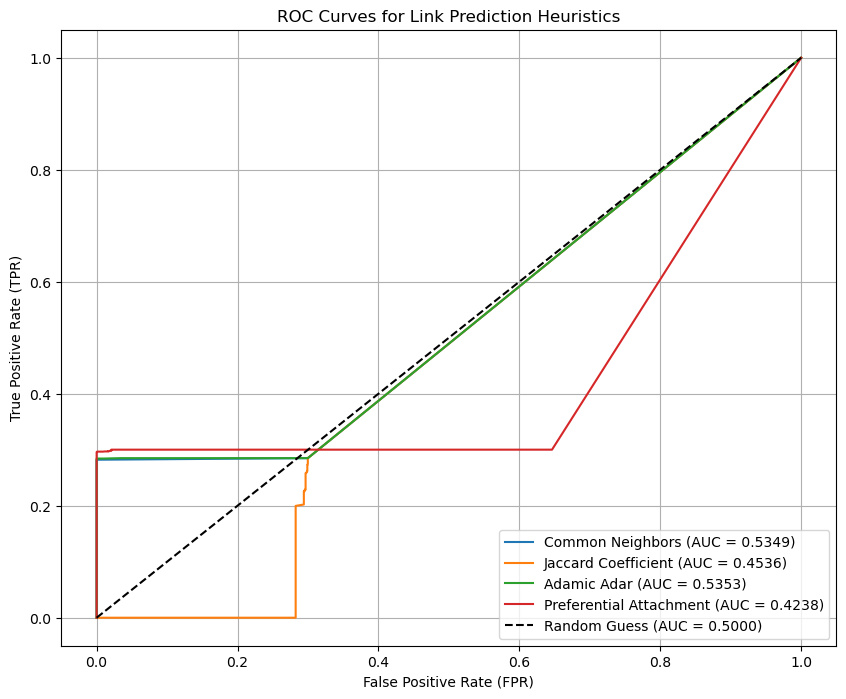

In [16]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Creiamo un dizionario con i risultati calcolati
results = {
    "Common Neighbors": score_cn,
    "Jaccard Coefficient": score_jc,
    "Adamic Adar": score_aa,
    "Preferential Attachment": score_pa
}

plt.figure(figsize=(10, 8))

# Iteriamo per ogni metrica e plottiamo la curva
for name, scores in results.items():
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc = roc_auc_score(y_true, scores)
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.4f})')

# Aggiungiamo la linea di riferimento (random guessing)
plt.plot([0, 1], [0, 1], 'k--', label='Random Guess (AUC = 0.5000)')

plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('ROC Curves for Link Prediction Heuristics')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()